In [1]:
!pip install langchain-groq


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [langchain-groq]


In [2]:
from google.colab import userdata
groq_api_key=userdata.get("GROQ_API_KEY")


In [3]:
from google.colab import userdata
groq_api_key=userdata.get("GROQ_API_KEY")
from langchain_groq import ChatGroq
from langchain_core.prompts import ChatPromptTemplate
llm = ChatGroq(
    groq_api_key=groq_api_key,
    model="openai/gpt-oss-120b",
    temperature=0,
)

### Step 1:Define the Schema

In [4]:
from typing import TypedDict,List

In [5]:
from typing import TypedDict,List,Annotated
from langgraph.graph.message import add_messages
class graph_schema(TypedDict):
  messages: Annotated[List,add_messages]


### Step2:create the node Function

In [6]:
def welcome(state:graph_schema)->graph_schema:

  curr_message=state['messages']
  response=llm.invoke(curr_message).content
  # change the current state message (user message) to AI message
  state['messages']=f"your message was {curr_message}.Here is my response: {response}"
  return state

### Step3:create The State Graph

In [7]:
from langgraph.graph import StateGraph,START,END
graph= StateGraph(graph_schema)
#Adding node
graph.add_node("Welcome",welcome)

#add edge of the node start and end point
graph.add_edge(START,"Welcome")
graph.add_edge("Welcome",END)

### Step 4: Complie the graph with checkpoint

In [8]:
first_graph=graph.compile()

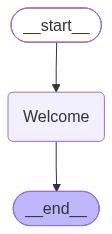

In [9]:
from IPython.display import Image,display
from langgraph.checkpoint.memory import InMemorySaver
checkpoint= InMemorySaver()
memory_graph=graph.compile(checkpointer=checkpoint)
#You could see errors with the below cmnd
Image(memory_graph.get_graph().draw_mermaid_png())


In [10]:
#then you can use the below cmnd to see the graph code not the graph without errors
print(memory_graph.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	Welcome(Welcome)
	__end__([<p>__end__</p>]):::last
	__start__ --> Welcome;
	Welcome --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [11]:
#to see the exact graph with the given graph code which is above output ,paste the code in mermid website

### Step5- Run the Graph with Config

In [12]:
memory_graph.invoke(
    {"messages":"My name is Biswajit"},
    {'configurable':{'thread_id':'biswajit'}}
)



{'messages': [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='d2554172-13d7-42ef-bc21-5cbff4fba05d'),
  HumanMessage(content="your message was [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='d2554172-13d7-42ef-bc21-5cbff4fba05d')].Here is my response: Nice to meet you, Biswajit! How can I assist you today?", additional_kwargs={}, response_metadata={}, id='464277ef-1c2e-4fee-b8b2-c57ea7b111f8')]}

In [13]:
response= memory_graph.invoke(
    {"messages":"My name is Biswajit"},
    {'configurable':{'thread_id':'tukun'}}
)

for message in response['messages']:
  message.pretty_print()


================================ Human Message =================================

My name is Biswajit
================================ Human Message =================================

your message was [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='2c9aa9f8-7dfc-4e16-be85-aaf5b9369440')].Here is my response: Nice to meet you, Biswajit! How can I assist you today?


# 2nd question when i asked in same thread it should remember the data as per the memory

In [14]:
response= memory_graph.invoke(
    {"messages":"What is my name "},
    {'configurable':{'thread_id':'tukun'}}
)

for message in response['messages']:
  message.pretty_print()


================================ Human Message =================================

My name is Biswajit
================================ Human Message =================================

your message was [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='2c9aa9f8-7dfc-4e16-be85-aaf5b9369440')].Here is my response: Nice to meet you, Biswajit! How can I assist you today?
================================ Human Message =================================

What is my name 
================================ Human Message =================================

your message was [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='2c9aa9f8-7dfc-4e16-be85-aaf5b9369440'), HumanMessage(content="your message was [HumanMessage(content='My name is Biswajit', additional_kwargs={}, response_metadata={}, id='2c9aa9f8-7dfc-4e16-be85-aaf5b9369440')].Here is my response: Nice to meet you, Biswajit! How can I assist you today?", additio